<a href="https://colab.research.google.com/github/Finoria-co/fridge-chef-ai/blob/main/add_thai_sources.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# เพิ่มชุดข้อมูล Roboflow หลายชุดเข้า foodseg_fridge_yolo

## ติดตั้งและเชื่อม Drive

In [1]:
!pip install -q roboflow ultralytics
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## ตั้งค่า


In [2]:
SOURCES = [
    dict(workspace="recipe-raw",              project="object-detection-raw-ingredient", version=None, repeat=1),
    dict(workspace="napassada-potipak-wedon", project="5-thai-herbs",                    version=None, repeat=2),
]

DRIVE_DIR = "/content/drive/MyDrive/fridge_project"
BASE_ZIP  = f"{DRIVE_DIR}/foodseg_fridge_yolo.zip"        # ชุดที่ทำไว้แล้ว (71 คลาส)
OUT_ZIP   = f"{DRIVE_DIR}/foodseg_fridge_thai_yolo.zip"   # ชุดใหม่
SRC_ROOT  = "/content/rf_sources"
BASE_DIR  = "/content/foodseg_yolo"
MIN_TRAIN = 20     # คลาสที่มีวัตถุใน train น้อยกว่านี้จะถูกตัดทิ้งตอนท้าย

## ดาวน์โหลด

In [3]:
import os, glob, yaml, collections, shutil
from roboflow import Roboflow
try:
    from google.colab import userdata
    API_KEY = userdata.get("ROBOFLOW_API_KEY")
except Exception:
    from getpass import getpass
    API_KEY = getpass("Roboflow API key: ")

rf = Roboflow(api_key=API_KEY)
ready = []   # ชุดที่ดาวน์โหลดได้และใช้ได้
for s in SOURCES:
    tag = s["project"]
    print(f"\n=== {s['workspace']}/{tag} ===")
    try:
        proj = rf.workspace(s["workspace"]).project(tag)
    except Exception as e:
        print("  เปิดโปรเจกต์ไม่ได้:", e); continue
    print(f"  ชนิดงาน: {proj.type} | คลาส: {proj.classes}")
    if "classification" in str(proj.type):
        print("  ⏭ ข้าม: เป็นงาน classification ไม่มีกรอบให้ใช้"); continue
    vs = proj.versions()
    if not vs:
        print("  ⏭ ข้าม: โปรเจกต์นี้ยังไม่มี version ให้ดาวน์โหลด"); continue
    nums = sorted(int(str(v.version).split("/")[-1]) for v in vs)
    ver = s["version"] or nums[-1]
    print(f"  เวอร์ชันที่มี: {nums} -> ใช้ v{ver}")
    loc = f"{SRC_ROOT}/{tag}"
    v = proj.version(ver)
    try:
        v.download("yolov11", location=loc, overwrite=True)
    except Exception as e:
        print("  yolov11 ไม่ได้ ลอง yolov8:", e)
        v.download("yolov8", location=loc, overwrite=True)
    ready.append(dict(s, tag=tag, dir=loc, ver=ver))
print("\nพร้อมใช้:", [r["tag"] for r in ready])


=== recipe-raw/object-detection-raw-ingredient ===
loading Roboflow workspace...
loading Roboflow project...
  ชนิดงาน: object-detection | คลาส: {}
  ⏭ ข้าม: โปรเจกต์นี้ยังไม่มี version ให้ดาวน์โหลด

=== napassada-potipak-wedon/5-thai-herbs ===
loading Roboflow workspace...
loading Roboflow project...
  ชนิดงาน: object-detection | คลาส: {'Basil': 702, 'Holy-Basil': 701, 'Peppermint': 705, 'Bergamot': 705, 'Wild-Betel': 704}
  เวอร์ชันที่มี: [1, 2, 3, 4, 5, 6, 7, 8, 9] -> ใช้ v9



Extracting Dataset Version Zip to /content/rf_sources/5-thai-herbs in yolov11:: 100%|██████████| 3149/3149 [00:00<00:00, 5607.72it/s]


พร้อมใช้: ['5-thai-herbs']


## สำรวจทีละชุด

In [4]:
def load_names(path):
    n = yaml.safe_load(open(path))["names"]
    return [n[i] for i in sorted(n)] if isinstance(n, dict) else list(n)

def label_kind(split_dir):
    kind = collections.Counter()
    for f in glob.glob(f"{split_dir}/labels/*.txt"):
        for line in open(f):
            n = len(line.split())
            if n: kind["box" if n == 5 else "polygon"] += 1
    return kind

for r in ready:
    r["splits"] = [sp for sp in ("train", "valid", "test") if os.path.isdir(f"{r['dir']}/{sp}/images")]
    r["names"] = load_names(f"{r['dir']}/data.yaml")
    print(f"\n=== {r['tag']} v{r['ver']} ({len(r['names'])} คลาส) ===\n  {r['names']}")
    for sp in r["splits"]:
        d = f"{r['dir']}/{sp}"
        n_img = len(glob.glob(f"{d}/images/*"))
        print(f"  {sp}: {n_img} ภาพ, label: {dict(label_kind(d))}")


=== 5-thai-herbs v9 (5 คลาส) ===
  ['Basil', 'Bergamot', 'Holy-Basil', 'Peppermint', 'Wild-Betel']
  train: 1398 ภาพ, label: {'box': 7479, 'polygon': 117}
  valid: 100 ภาพ, label: {'box': 503, 'polygon': 1}
  test: 74 ภาพ, label: {'box': 479, 'polygon': 2}


## แปลงกรอบเป็น polygon ด้วย SAM

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

=== 5-thai-herbs ===
Fast image access ✅ (ping: 0.0±0.0 ms, read: 1386.5±515.1 MB/s, size: 55.1 KB)
Scanning /content/rf_sources/5-thai-herbs/train/labels... 1398 images, 0 backgrounds, 45 corrupt: 100% ━━━━━━━━━━━━ 1398/1398 1.8Kit/s 0.8s
/content/rf_sources/5-thai-herbs/train/images/IMG_6268_640_JPG.rf.1ca947e7d47a0747d1f1f49989870bca.jpg: ignoring corrupt image/label: labels mix segment and detection rows
/content/rf_sources/5-thai-herbs/train/images/IMG_6268_640_JPG.rf.91941ccb2253711456bc35ed357c43d3.jpg: ignoring corrupt image/label: labels mix segment and detection rows
/content/rf_sources/5-thai-herbs/train/images/IMG_6268_640_JPG.rf.972d79dbc1e7e7e3e36d28081d929bbf.jpg: ignoring corrupt im

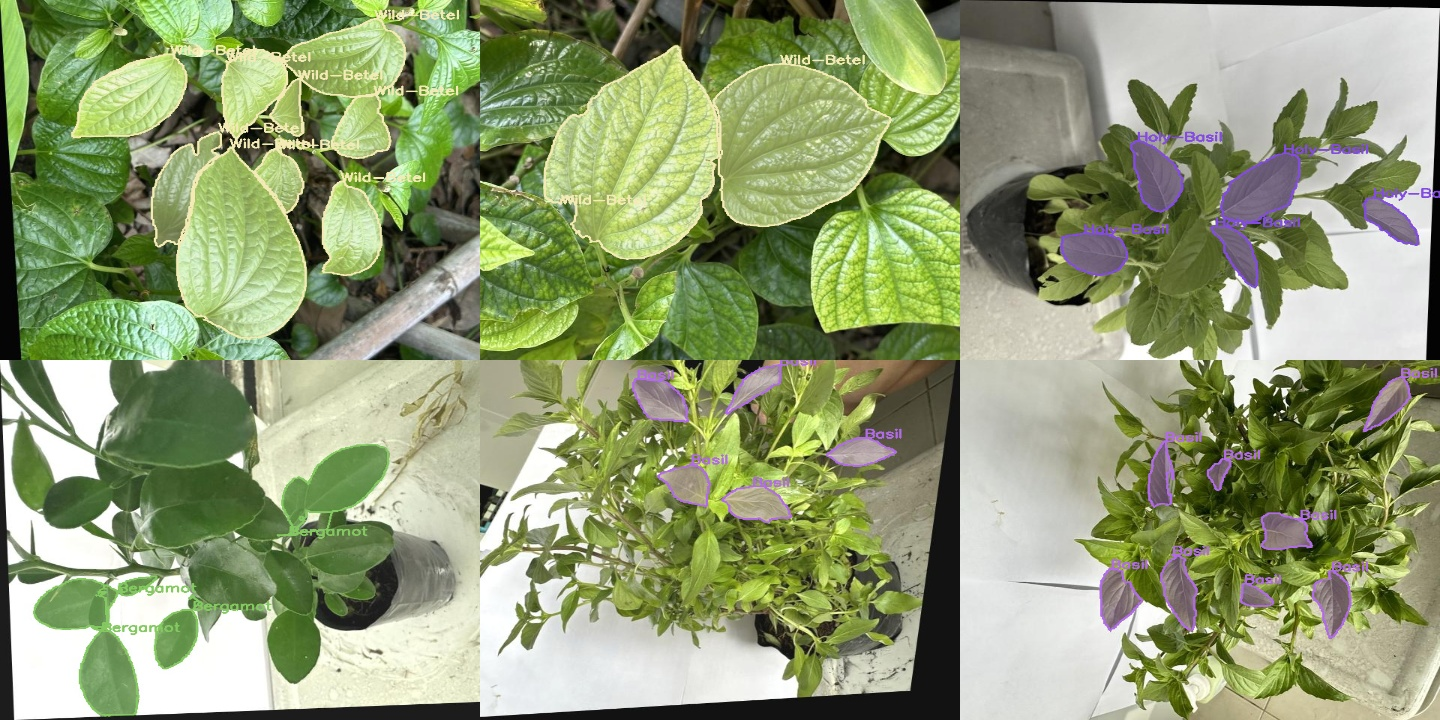

In [5]:
import cv2, numpy as np, random
from IPython.display import Image as Show, display
from ultralytics.data.converter import yolo_bbox2segment

def draw_grid(img_dir, names, out, n=6, seed=0):
    imgs = sorted(glob.glob(f"{img_dir}/*"))
    if not imgs: print("  ไม่มีภาพ"); return
    random.seed(seed); tiles = []
    for p in random.sample(imgs, min(n, len(imgs))):
        im = cv2.imread(p); h, w = im.shape[:2]
        lbl = os.path.join(os.path.dirname(os.path.dirname(p)), "labels",
                           os.path.splitext(os.path.basename(p))[0] + ".txt")
        for line in (open(lbl).read().splitlines() if os.path.exists(lbl) else []):
            v = line.split()
            if len(v) < 7: continue
            c = int(v[0])
            pts = (np.array(v[1:], float).reshape(-1, 2) * [w, h]).astype(np.int32)
            col = [int(x) for x in np.random.RandomState(c).randint(60, 255, 3)]
            ov = im.copy(); cv2.fillPoly(ov, [pts], col); im = cv2.addWeighted(ov, 0.4, im, 0.6, 0)
            cv2.polylines(im, [pts], True, col, 2)
            cv2.putText(im, str(names[c]), tuple(pts[0]), cv2.FONT_HERSHEY_SIMPLEX, 0.7, col, 2)
        tiles.append(cv2.resize(im, (480, 360)))
    while len(tiles) % 3: tiles.append(np.zeros_like(tiles[0]))
    grid = np.vstack([np.hstack(tiles[i:i+3]) for i in range(0, len(tiles), 3)])
    cv2.imwrite(out, grid); display(Show(out))

for r in ready:
    print(f"\n=== {r['tag']} ===")
    for sp in r["splits"]:
        d = f"{r['dir']}/{sp}"
        if label_kind(d)["box"] == 0:
            print(f"  {sp}: เป็น polygon แล้ว ข้าม"); continue
        yolo_bbox2segment(im_dir=f"{d}/images", save_dir=f"{d}/labels_seg", sam_model="sam_b.pt")
        if not os.path.isdir(f"{d}/labels_box"): shutil.move(f"{d}/labels", f"{d}/labels_box")
        shutil.rmtree(f"{d}/labels", ignore_errors=True)
        shutil.move(f"{d}/labels_seg", f"{d}/labels")
        print(f"  {sp}: แปลงแล้ว ->", dict(label_kind(d)))
    draw_grid(f"{r['dir']}/train/images", r["names"], f"/content/check_{r['tag']}.jpg")

## แตกชุดฐาน foodseg_fridge_yolo.zip

In [6]:
assert os.path.exists(BASE_ZIP), f"ไม่พบไฟล์: {BASE_ZIP}"
shutil.rmtree(BASE_DIR, ignore_errors=True)
!unzip -q "{BASE_ZIP}" -d /content
base_names = load_names(f"{BASE_DIR}/data.yaml")
print(f"ชุดฐานมี {len(base_names)} คลาส")
for i, n in enumerate(base_names):
    print(f"{i:>3}: {n:<22}", end="\n" if (i + 1) % 4 == 0 else "")
print()

ชุดฐานมี 71 คลาส
  0: cheese butter           1: milk                    2: egg                     3: apple                 
  4: avocado                 5: banana                  6: strawberry              7: mango                 
  8: lemon                   9: grape                  10: orange                 11: steak                 
 12: pork                   13: chicken duck           14: sausage                15: fish                  
 16: shellfish              17: shrimp                 18: bread                  19: corn                  
 20: tofu                   21: eggplant               22: potato                 23: garlic                
 24: cauliflower            25: tomato                 26: spring onion           27: rape                  
 28: ginger                 29: okra                   30: lettuce                31: pumpkin               
 32: cucumber               33: white radish           34: carrot                 35: asparagus             
 3

##  จับคู่ชื่อคลาส

In [13]:
MERGE = {
    "basil": "sweet basil",
    "bergamot": "kaffir lime",
    "peppermint": "cilantro mint",
}
DROP = []

known = [n.lower() for n in base_names]
def norm(n):
    n = n.strip().lower().replace("_", " ").replace("-", " ").strip()
    n = " ".join(n.split())
    n = MERGE.get(n, n)
    for suf in ("es", "s"):
        if n.endswith(suf) and n[:-len(suf)] in known:
            return n[:-len(suf)]
    return n

all_names = list(base_names)
for r in ready:
    r["plan"] = {}
    print(f"\n=== {r['tag']} ===")
    for i, n in enumerate(r["names"]):
        t = norm(n)
        if t in DROP or not t:
            r["plan"][i] = None; print(f"  {n!r:<28} -> ตัดทิ้ง"); continue
        if t not in known:
            known.append(t); all_names.append(t)
            print(f"  {n!r:<28} -> คลาสใหม่ {known.index(t)}: {t}")
        else:
            print(f"  {n!r:<28} -> {known.index(t)}: {all_names[known.index(t)]}")
        r["plan"][i] = known.index(t)
print(f"\nรวมทั้งหมด {len(all_names)} คลาส (ก่อนตัดคลาสที่ตัวอย่างน้อย)")


=== 5-thai-herbs ===
  'Basil'                      -> คลาสใหม่ 71: sweet basil
  'Bergamot'                   -> คลาสใหม่ 72: kaffir lime
  'Holy-Basil'                 -> คลาสใหม่ 73: holy basil
  'Peppermint'                 -> 38: cilantro mint
  'Wild-Betel'                 -> คลาสใหม่ 74: wild betel

รวมทั้งหมด 75 คลาส (ก่อนตัดคลาสที่ตัวอย่างน้อย)


## รวมชุดข้อมูล


In [14]:
added = collections.Counter()
for r in ready:
    for rf_split, split, rep in (("train", "train", r["repeat"]), ("valid", "val", 1), ("test", "val", 1)):
        if rf_split not in r["splits"]: continue
        for p in glob.glob(f"{r['dir']}/{rf_split}/images/*"):
            stem, ext = os.path.splitext(os.path.basename(p))
            lbl = f"{r['dir']}/{rf_split}/labels/{stem}.txt"
            out = []
            for line in (open(lbl).read().splitlines() if os.path.exists(lbl) else []):
                v = line.split()
                if len(v) < 7: continue
                c = r["plan"][int(v[0])]
                if c is None: continue
                out.append(" ".join([str(c)] + v[1:]))
            for k in range(rep):
                name = f"{r['tag']}_{rf_split}_{stem}_r{k}"
                shutil.copy(p, f"{BASE_DIR}/images/{split}/{name}{ext}")
                with open(f"{BASE_DIR}/labels/{split}/{name}.txt", "w") as f:
                    f.write("\n".join(out))
                added[(r["tag"], split)] += 1
for (tag, split), n in sorted(added.items()):
    print(f"  {tag}: +{n} ภาพ -> {split}")

  5-thai-herbs: +2796 ภาพ -> train
  5-thai-herbs: +174 ภาพ -> val


## ตัดคลาสที่ตัวอย่างน้อย แล้วเรียงเลขคลาสใหม่

In [15]:
files = {s: glob.glob(f"{BASE_DIR}/labels/{s}/*.txt") for s in ("train", "val")}
count = collections.Counter()
for f in files["train"]:
    for line in open(f):
        v = line.split()
        if v: count[int(v[0])] += 1

keep = [i for i in range(len(all_names)) if count[i] >= MIN_TRAIN]
dropped = [(all_names[i], count[i]) for i in range(len(all_names)) if count[i] < MIN_TRAIN]
old2new = {old: new for new, old in enumerate(keep)}
removed = collections.Counter()
for s, fs in files.items():
    for f in fs:
        out = []
        for line in open(f).read().splitlines():
            v = line.split()
            if not v: continue
            c = old2new.get(int(v[0]))
            if c is None: removed[s] += 1; continue
            out.append(" ".join([str(c)] + v[1:]))
        with open(f, "w") as fh: fh.write("\n".join(out))

final_names = [all_names[i] for i in keep]
cfg = yaml.safe_load(open(f"{BASE_DIR}/data.yaml"))
cfg.update(path=BASE_DIR, nc=len(final_names), names={i: n for i, n in enumerate(final_names)})
yaml.safe_dump(cfg, open(f"{BASE_DIR}/data.yaml", "w"), allow_unicode=True, sort_keys=False)
for f in glob.glob(f"{BASE_DIR}/labels/*.cache"): os.remove(f)

print(f"คลาส: {len(all_names)} -> {len(final_names)} | วัตถุที่ถูกตัด: train {removed['train']}, val {removed['val']}")
print(f"คลาสที่ตัดทิ้ง (< {MIN_TRAIN} ใน train):", ", ".join(f"{n}({c})" for n, c in dropped) or "-")

คลาส: 75 -> 75 | วัตถุที่ถูกตัด: train 0, val 0
คลาสที่ตัดทิ้ง (< 20 ใน train): -


## ตรวจชุดที่รวมแล้ว

In [16]:
nc = len(final_names); per_class = collections.Counter()
for split in ("train", "val"):
    imgs = {os.path.splitext(os.path.basename(p))[0] for p in glob.glob(f"{BASE_DIR}/images/{split}/*")}
    lbls = {os.path.splitext(os.path.basename(p))[0] for p in glob.glob(f"{BASE_DIR}/labels/{split}/*.txt")}
    bad = collections.Counter()
    for k in lbls:
        for line in open(f"{BASE_DIR}/labels/{split}/{k}.txt").read().splitlines():
            v = line.split()
            if not v: continue
            c = int(v[0]); xy = [float(x) for x in v[1:]]
            bad["คลาสเกิน nc"] += not (0 <= c < nc)
            bad["จุดไม่ครบ"] += (len(xy) % 2 == 1 or len(xy) < 6)
            bad["พิกัดนอก 0-1"] += any(x < 0 or x > 1 for x in xy)
            if split == "train": per_class[c] += 1
    by_src = collections.Counter(next((r["tag"] for r in ready if k.startswith(r["tag"] + "_")), "เดิม") for k in imgs)
    print(f"[{split}] ภาพ {len(imgs)} | label {len(lbls)} | ไม่มีคู่ {len(imgs ^ lbls)} | ที่มา {dict(by_src)} | ปัญหา {dict(bad)}")

print("\nคลาสใหม่ที่เพิ่มเข้ามา (จำนวนวัตถุใน train):")
for i, n in enumerate(final_names):
    if n not in [b.lower() for b in base_names]:
        print(f"  {i}: {n} = {per_class[i]}")

[train] ภาพ 10055 | label 10055 | ไม่มีคู่ 0 | ที่มา {'5-thai-herbs': 2796, 'เดิม': 7259} | ปัญหา {'คลาสเกิน nc': 0, 'จุดไม่ครบ': 0, 'พิกัดนอก 0-1': 0}
[val] ภาพ 3276 | label 3276 | ไม่มีคู่ 0 | ที่มา {'เดิม': 3102, '5-thai-herbs': 174} | ปัญหา {'คลาสเกิน nc': 0, 'จุดไม่ครบ': 0, 'พิกัดนอก 0-1': 0}

คลาสใหม่ที่เพิ่มเข้ามา (จำนวนวัตถุใน train):
  71: sweet basil = 2724
  72: kaffir lime = 3264
  73: holy basil = 3216
  74: wild betel = 2184


5-thai-herbs


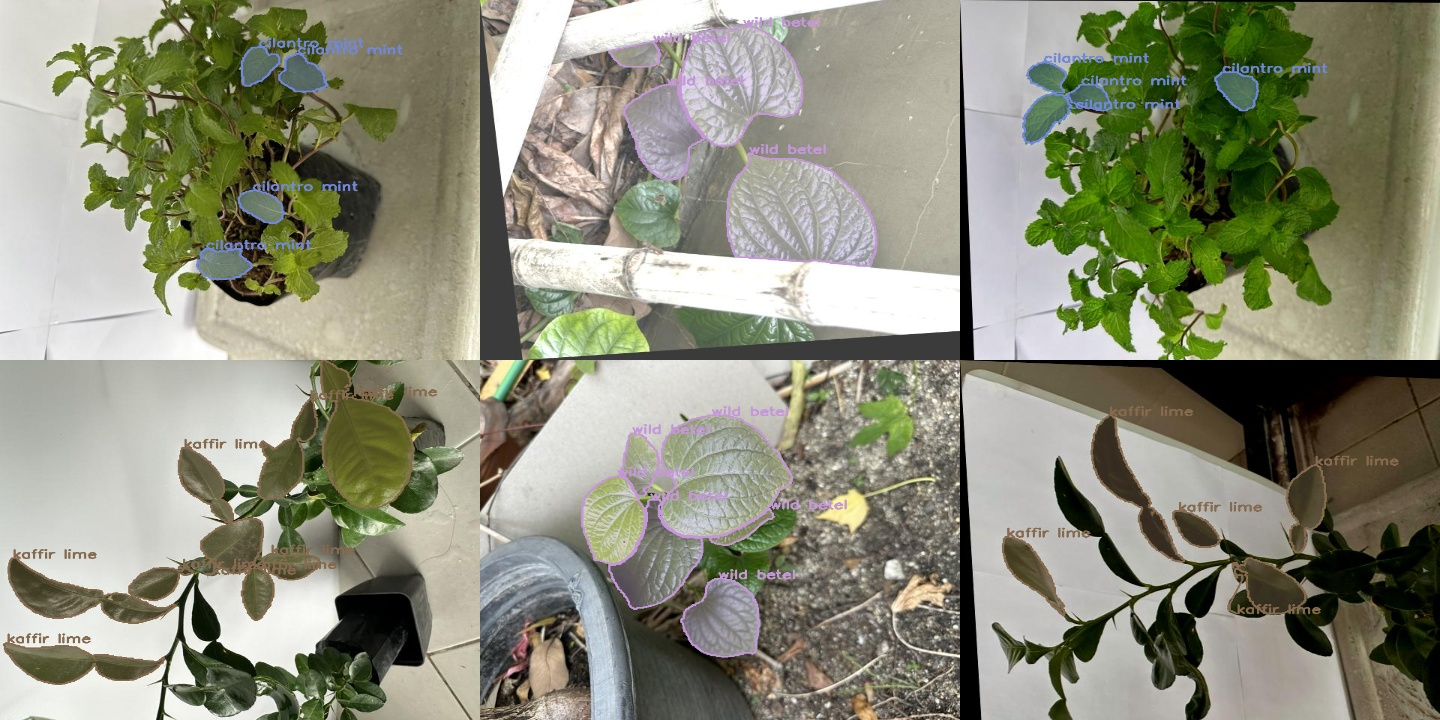

In [17]:
for r in ready:
    fr = glob.glob(f"{BASE_DIR}/images/train/{r['tag']}_*")
    if not fr: continue
    peek = f"/content/_peek_{r['tag']}"; shutil.rmtree(peek, ignore_errors=True)
    os.makedirs(f"{peek}/images"); os.makedirs(f"{peek}/labels")
    for p in random.sample(fr, min(6, len(fr))):
        stem = os.path.splitext(os.path.basename(p))[0]
        shutil.copy(p, f"{peek}/images"); shutil.copy(f"{BASE_DIR}/labels/train/{stem}.txt", f"{peek}/labels")
    print(r["tag"]); draw_grid(f"{peek}/images", final_names, f"/content/check_merged_{r['tag']}.jpg", seed=1)

## บีบอัดขึ้น Drive

In [18]:
%cd /content
!rm -f /content/out.zip
!zip -qr /content/out.zip foodseg_yolo
!cp /content/out.zip "{OUT_ZIP}"
!ls -lh "{DRIVE_DIR}"

/content
total 4.4G
-rw------- 1 root root 4.9K Nov 10 06:50 convert_foodseg103.py
-rw------- 1 root root 1.7G Nov 11 13:51 foodseg_fridge_thai_yolo.zip
-rw------- 1 root root 1.5G Nov 10 09:50 foodseg_fridge_yolo.zip
-rw------- 1 root root 1.3G Nov 10 09:30 foodseg_yolo.zip
drwx------ 2 root root 4.0K Nov 10 06:50 test_yolo
